# Auditoría del modelo de Machine Learning

El objetivo de este notebook es cargar el modelo KNN entrenado, verificar sus características y comprobar que puede reproducir las predicciones obtenidas durante la etapa de evaluación.

In [39]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

## 1. Configuración del proyecto

Definimos la raíz del proyecto y las rutas de los archivos que vamos a utilizar.

In [40]:

ROOT = Path.cwd() if Path.cwd().name != "notebooks" else Path.cwd().parent

MODEL_PATH = ROOT / "results" / "models" / "knn_full_unweighted.joblib"
TEST_PATH = ROOT / "data" / "processed" / "ml_test_full.csv"
PREDICTIONS_PATH = ROOT / "results" / "predictions" / "test_predictions_all_models.csv"

print("Raíz del proyecto:", ROOT)
print("Modelo encontrado:", MODEL_PATH.exists())
print("Dataset de prueba encontrado:", TEST_PATH.exists())
print("Predicciones originales encontradas:", PREDICTIONS_PATH.exists())

Raíz del proyecto: /home/anton/Tp-Grafos-ML
Modelo encontrado: True
Dataset de prueba encontrado: True
Predicciones originales encontradas: True


## 2. Carga e inspección del modelo

Cargamos el modelo KNN previamente entrenado mediante Joblib. No realizamos un nuevo entrenamiento.

In [41]:
model = joblib.load(MODEL_PATH)

print("Modelo cargado correctamente")
print(type(model))
print(model)

Modelo cargado correctamente
<class 'sklearn.pipeline.Pipeline'>
Pipeline(steps=[('scaler', StandardScaler()),
                ('clf', KNeighborsClassifier(n_jobs=-1, n_neighbors=15))])


### Características esperadas por el modelo

Inspeccionamos las variables de entrada y las clases que puede predecir el clasificador.

In [42]:
print("Features esperadas:")
print(model.feature_names_in_)

print("\nClases:")
print(model.classes_)

print("\nCantidad de features:")
print(len(model.feature_names_in_))

Features esperadas:
['mismo_departamento' 'mismo_prefijo_curricular' 'anio_confirmado'
 'mismo_anio' 'misma_carrera' 'cant_carreras_compartidas_hist'
 'cant_inscriptos_hist_1' 'cant_inscriptos_hist_2'
 'cant_estudiantes_compartidos_historico' 'jaccard_historico']

Clases:
[0 1]

Cantidad de features:
10


## 3. Carga del conjunto de prueba

Cargamos el dataset utilizado durante la evaluación del modelo para comprobar que podemos reproducir sus resultados.

In [43]:
df_test = pd.read_csv(TEST_PATH)

print("Dimensiones:", df_test.shape)

print("\nColumnas:")
print(df_test.columns.tolist())

df_test.head()

Dimensiones: (65059, 15)

Columnas:
['materia_id_1', 'materia_id_2', 'mismo_departamento', 'mismo_prefijo_curricular', 'anio_confirmado', 'mismo_anio', 'misma_carrera', 'cant_carreras_compartidas_hist', 'cant_inscriptos_hist_1', 'cant_inscriptos_hist_2', 'cant_estudiantes_compartidos_historico', 'tasa_compartidos_historico', 'jaccard_historico', 'cant_estudiantes_afectados', 'hubo_conflicto_potencial']


,materia_id_1,materia_id_2,mismo_departamento,mismo_prefijo_curricular,anio_confirmado,mismo_anio,misma_carrera,cant_carreras_compartidas_hist,cant_inscriptos_hist_1,cant_inscriptos_hist_2,cant_estudiantes_compartidos_historico,tasa_compartidos_historico,jaccard_historico,cant_estudiantes_afectados,hubo_conflicto_potencial
0,AA2016E1,AAA034E1,False,True,False,False,True,2,19,15,0,0.0,0.0,0,False
1,AA2016E1,B12301E1,False,False,True,True,False,0,19,16,0,0.0,0.0,0,False
2,AA2016E1,B32322E1,False,False,True,True,False,0,19,110,0,0.0,0.0,0,False
3,AA2016E1,C11101E1,False,False,True,False,False,0,19,3,0,0.0,0.0,0,False
4,AA2016E1,C11105E1,False,False,True,False,False,0,19,1,0,0.0,0.0,0,False


### Separación de variables predictoras y objetivo

Seleccionamos exclusivamente las 10 características utilizadas durante el entrenamiento.

Separamos también la variable objetivo, que contiene los resultados reales que utilizaremos para evaluar las predicciones.

In [44]:
FEATURES = list(model.feature_names_in_)

X_test = df_test[FEATURES]
y_test = df_test["hubo_conflicto_potencial"]

print("Dimensiones de X:", X_test.shape)
print("Dimensiones de y:", y_test.shape)

print("\nValores nulos:", X_test.isnull().sum().sum())

print("\nDistribución del objetivo:")
print(y_test.value_counts())

Dimensiones de X: (65059, 10)
Dimensiones de y: (65059,)

Valores nulos: 0

Distribución del objetivo:
hubo_conflicto_potencial
False    64089
True       970
Name: count, dtype: int64


### Control de calidad de los datos

Comprobamos que las características no contengan valores infinitos que puedan afectar la inferencia del modelo.

In [45]:
valores_infinitos = np.isinf(
    X_test.select_dtypes(include="number")
).sum().sum()

print("Valores infinitos:", valores_infinitos)

Valores infinitos: 0


## 4. Inferencia del modelo

Utilizamos el modelo KNN previamente entrenado para calcular la probabilidad de conflicto de cada par de materias del conjunto de prueba.

No entrenamos nuevamente el modelo. Solamente realizamos inferencia.

In [46]:
probabilidades = model.predict_proba(X_test)[:, 1]

print("Cantidad de predicciones:", len(probabilidades))
print("Probabilidad mínima:", probabilidades.min())
print("Probabilidad máxima:", probabilidades.max())

print("\nPrimeras 20 probabilidades:")
print(probabilidades[:20])

Cantidad de predicciones: 65059
Probabilidad mínima: 0.0
Probabilidad máxima: 0.9333333333333333

Primeras 20 probabilidades:
[0.06666667 0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.        ]


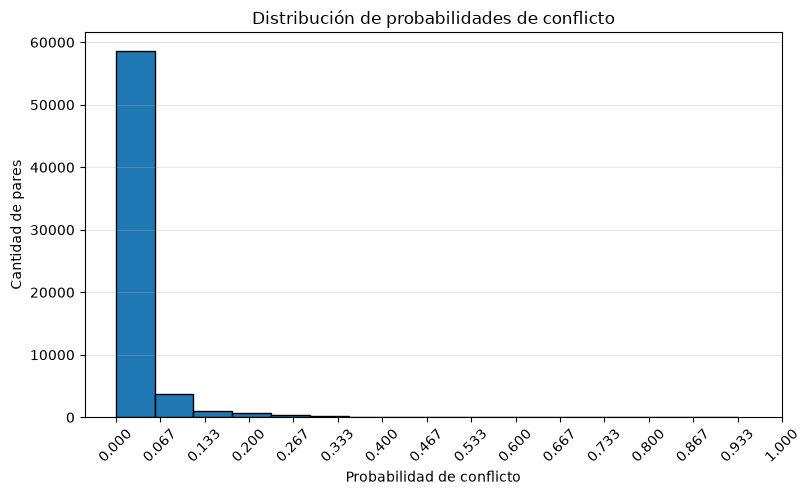

In [47]:

plt.figure(figsize=(9, 5))
plt.hist(probabilidades, bins=16, edgecolor="black")
plt.title("Distribución de probabilidades de conflicto")
plt.xlabel("Probabilidad de conflicto")
plt.ylabel("Cantidad de pares")
plt.xticks(np.arange(0, 1.01, 1/15), rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.show()

## 5. Verificación de reproducibilidad

Comparamos las probabilidades obtenidas al cargar el modelo con las que quedaron almacenadas durante la evaluación original.

También verificamos que ambos archivos contengan los mismos pares de materias y en el mismo orden.

In [48]:
df_predictions = pd.read_csv(PREDICTIONS_PATH)

print("Dimensiones:", df_predictions.shape)
print("\nColumnas:")
print(df_predictions.columns.tolist())

Dimensiones: (65059, 31)

Columnas:
['materia_id_1', 'materia_id_2', 'hubo_conflicto_potencial', 'prob_Baseline_Mayoritario', 'pred_Baseline_Mayoritario_th050', 'prob_Baseline_Heuristico_Historico', 'pred_Baseline_Heuristico_Historico_th050', 'prob_DecisionTree_Balanced', 'pred_DecisionTree_Balanced_th050', 'pred_DecisionTree_Balanced_thVal', 'prob_LogisticRegression_Balanced', 'pred_LogisticRegression_Balanced_th050', 'pred_LogisticRegression_Balanced_thVal', 'prob_KNN_Balanced', 'pred_KNN_Balanced_th050', 'pred_KNN_Balanced_thVal', 'prob_DecisionTree_Full_Unweighted', 'pred_DecisionTree_Full_Unweighted_th050', 'pred_DecisionTree_Full_Unweighted_thVal', 'prob_DecisionTree_Full_ClassWeight', 'pred_DecisionTree_Full_ClassWeight_th050', 'pred_DecisionTree_Full_ClassWeight_thVal', 'prob_LogisticRegression_Full_Unweighted', 'pred_LogisticRegression_Full_Unweighted_th050', 'pred_LogisticRegression_Full_Unweighted_thVal', 'prob_LogisticRegression_Full_ClassWeight', 'pred_LogisticRegression_F

In [49]:
assert len(df_test) == len(df_predictions), "Los archivos tienen distinta cantidad de filas."

assert (
    df_test[["materia_id_1", "materia_id_2"]].reset_index(drop=True)
    .equals(
        df_predictions[["materia_id_1", "materia_id_2"]].reset_index(drop=True)
    )
), "Los pares de materias no coinciden o están en distinto orden."

print("Los pares de materias coinciden y están en el mismo orden.")

Los pares de materias coinciden y están en el mismo orden.


In [50]:
prob_col = "prob_KNN_Full_Unweighted"

assert prob_col in df_predictions.columns, f"No existe la columna {prob_col}"

probabilidades_originales = df_predictions[prob_col].to_numpy()

diferencia = np.abs(probabilidades - probabilidades_originales)

print("Diferencia máxima:", diferencia.max())

coinciden = np.allclose(
    probabilidades,
    probabilidades_originales,
    rtol=0,
    atol=1e-12
)

indices_diferentes = np.where(probabilidades != probabilidades_originales)[0]

print("Cantidad de diferencias:", len(indices_diferentes))

print("\nPrimeros casos:")
for i in indices_diferentes[:10]:
    print(
        f"Fila {i}: "
        f"modelo={probabilidades[i]:.12f} | "
        f"original={probabilidades_originales[i]:.12f} | "
        f"diferencia={diferencia[i]:.12f}"
    )

Diferencia máxima: 3.33333333379926e-07
Cantidad de diferencias: 5571

Primeros casos:
Fila 0: modelo=0.066666666667 | original=0.066667000000 | diferencia=0.000000333333
Fila 29: modelo=0.066666666667 | original=0.066667000000 | diferencia=0.000000333333
Fila 42: modelo=0.066666666667 | original=0.066667000000 | diferencia=0.000000333333
Fila 43: modelo=0.066666666667 | original=0.066667000000 | diferencia=0.000000333333
Fila 55: modelo=0.066666666667 | original=0.066667000000 | diferencia=0.000000333333
Fila 57: modelo=0.066666666667 | original=0.066667000000 | diferencia=0.000000333333
Fila 58: modelo=0.066666666667 | original=0.066667000000 | diferencia=0.000000333333
Fila 64: modelo=0.066666666667 | original=0.066667000000 | diferencia=0.000000333333
Fila 65: modelo=0.133333333333 | original=0.133333000000 | diferencia=0.000000333333
Fila 66: modelo=0.266666666667 | original=0.266667000000 | diferencia=0.000000333333


## 6. Evaluación del clasificador

Aplicamos el umbral de 0.21, seleccionado previamente durante la validación.

Si la probabilidad predicha es mayor o igual al umbral, clasificamos el par como un conflicto potencial (1). En caso contrario, lo clasificamos como ausencia de conflicto (0).

Evaluamos las predicciones comparándolas con los resultados reales del conjunto de prueba.

In [51]:
THRESHOLD = 0.21

predicciones = (probabilidades >= THRESHOLD).astype(int)

print("Umbral:", THRESHOLD)
print("Conflictos predichos:", predicciones.sum())
print("Pares sin conflicto predichos:", len(predicciones) - predicciones.sum())

Umbral: 0.21
Conflictos predichos: 889
Pares sin conflicto predichos: 64170


In [52]:
THRESHOLD = 0.21

predicciones_modelo = (probabilidades >= THRESHOLD).astype(int)

predicciones_originales = (
    probabilidades_originales >= THRESHOLD
).astype(int)

print(
    "Predicciones idénticas:",
    np.array_equal(predicciones_modelo, predicciones_originales)
)

print(
    "Cantidad de clasificaciones diferentes:",
    np.sum(predicciones_modelo != predicciones_originales)
)

Predicciones idénticas: True
Cantidad de clasificaciones diferentes: 0


In [53]:
pred_col = "pred_KNN_Full_Unweighted_thVal"

assert pred_col in df_predictions.columns, f"No existe la columna {pred_col}"

predicciones_originales = df_predictions[pred_col].astype(int).to_numpy()

coincidencia = np.mean(predicciones_modelo == predicciones_originales)

print("Porcentaje de coincidencia:", coincidencia * 100, "%")

assert np.array_equal(predicciones_modelo, predicciones_originales), (
    "Las predicciones no coinciden con las originales."
)

Porcentaje de coincidencia: 100.0 %


In [54]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

matriz = confusion_matrix(y_test.astype(int), predicciones_originales)

print("Matriz de confusión:")
print(matriz)

print("\nReporte de clasificación:")
print(
    classification_report(
        y_test.astype(int),
        predicciones_originales,
        target_names=["Sin conflicto", "Conflicto"]
    )
)

print("Precision:", precision_score(y_test.astype(int), predicciones_originales))
print("Recall:", recall_score(y_test.astype(int), predicciones_originales))
print("F1:", f1_score(y_test.astype(int), predicciones_originales))

Matriz de confusión:
[[63441   648]
 [  729   241]]

Reporte de clasificación:
               precision    recall  f1-score   support

Sin conflicto       0.99      0.99      0.99     64089
    Conflicto       0.27      0.25      0.26       970

     accuracy                           0.98     65059
    macro avg       0.63      0.62      0.62     65059
 weighted avg       0.98      0.98      0.98     65059

Precision: 0.27109111361079863
Recall: 0.24845360824742269
F1: 0.2592791823561054


## 7. Pruebas con distintos umbrales

Veremos que cómo cambia el resultado al modificar el umbral.

In [55]:
from sklearn.metrics import precision_score, recall_score, f1_score

umbrales = np.arange(0.05, 0.81, 0.05)

resultados_umbrales = []

for umbral in umbrales:
    pred = (probabilidades >= umbral).astype(int)

    resultados_umbrales.append({
        "umbral": round(umbral, 2),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "aristas_predichas": int(pred.sum())
    })

df_umbrales = pd.DataFrame(resultados_umbrales)

display(df_umbrales)

,umbral,precision,recall,f1,aristas_predichas
0,0.05,0.091193,0.601031,0.158359,6393
1,0.10,0.152709,0.415464,0.223331,2639
2,0.15,0.202862,0.336082,0.253007,1607
3,0.20,0.202862,0.336082,0.253007,1607
4,0.25,0.271091,0.248454,0.259279,889
5,0.30,0.337838,0.180412,0.235215,518
6,0.35,0.474747,0.145361,0.222573,297
7,0.40,0.474747,0.145361,0.222573,297
8,0.45,0.526316,0.123711,0.200334,228
9,0.50,0.559748,0.091753,0.157662,159


### Análisis de sensibilidad del umbral de clasificación

Se exploró el comportamiento del modelo KNN Full Unweighted utilizando distintos umbrales de clasificación sobre el conjunto de test, con el objetivo de observar cómo varían las métricas y la cantidad de pares clasificados como conflictivos.

Los resultados muestran el compromiso entre precision y recall:

- Los umbrales bajos permiten detectar una mayor proporción de conflictos reales, pero generan más falsos positivos.
- Los umbrales altos aumentan la precision, pero reducen considerablemente la cantidad de conflictos detectados.
- El mejor equilibrio observado en esta exploración se encuentra alrededor de 0.21–0.25, con un F1 de aproximadamente 0.259.

Se conserva el umbral **0.21**, seleccionado previamente mediante validación interna. No se modifica a partir de los resultados del conjunto de test, ya que este último se reserva para la evaluación final.

Además, debido a que el clasificador KNN utiliza 15 vecinos con ponderación uniforme, sus probabilidades se presentan en incrementos de aproximadamente 0.0667. Por esta razón, distintos umbrales pueden producir exactamente las mismas clasificaciones.

Este análisis permite comprender cómo el umbral afecta la construcción posterior del grafo, pero no constituye una evaluación de la calidad del cronograma generado.